# Linear regression: orbital period from distance

This notebook runs the linear regression part of the experiment and draws the graphs.
It uses the same functions as `experiment/run_experiment.py`, so the numbers are identical.

Start it from the project root with `uv run jupyter notebook experiment/regression.ipynb`, then choose *Run > Run All Cells*.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook lives in experiment/, so the project root (one level up) must be importable.
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from experiment.run_experiment import build_dataset, fit_regressions

Matplotlib is building the font cache; this may take a moment.


## 1. The data

`build_dataset()` reads distance and orbital period from the NASA PDF and adds the made-up body at 15 AU. Seven rows are for training and three are held back for testing.

In [2]:
rows = build_dataset()
train = [r for r in rows if r["split"] == "train"]
test = [r for r in rows if r["split"] == "test"]

print(f"{'body':<20}{'distance (AU)':>14}{'period (years)':>16}  split")
for r in rows:
    print(f"{r['body']:<20}{r['distance_au']:>14}{r['period_years']:>16}  {r['split']}")

body                 distance (AU)  period (years)  split
Mercury                     0.3871          0.2408  train
Venus                       0.7233          0.6152  train
Earth                          1.0             1.0  train
Mars                        1.5237          1.8807  test
Jupiter                     5.2033         11.8565  train
Saturn                      9.5365            29.4  train
Uranus                      19.191           84.02  test
Neptune                    30.0685          164.79  train
Pluto                      39.4811          247.92  train
Hypothetical body             15.0         58.0948  test


## 2. Train the two models

`fit_regressions()` trains on the train rows only:

- **log-log**: a straight line through log10(distance) and log10(period)
- **raw**: a straight line through the numbers as they are (the baseline)

In [3]:
predictions, fits = fit_regressions(train, test)

for name, fit in fits.items():
    print(f"{name:<7} slope = {fit['slope']:.4f}   intercept = {fit['intercept']:.4f}")

loglog  slope = 1.4998   intercept = -0.0001
raw     slope = 6.2399   intercept = -11.9006


## 3. The graphs

Left: on normal axes the data bends upward, so the straight (raw) line misses. Right: on log-log axes the same points lie on a straight line, so linear regression fits.

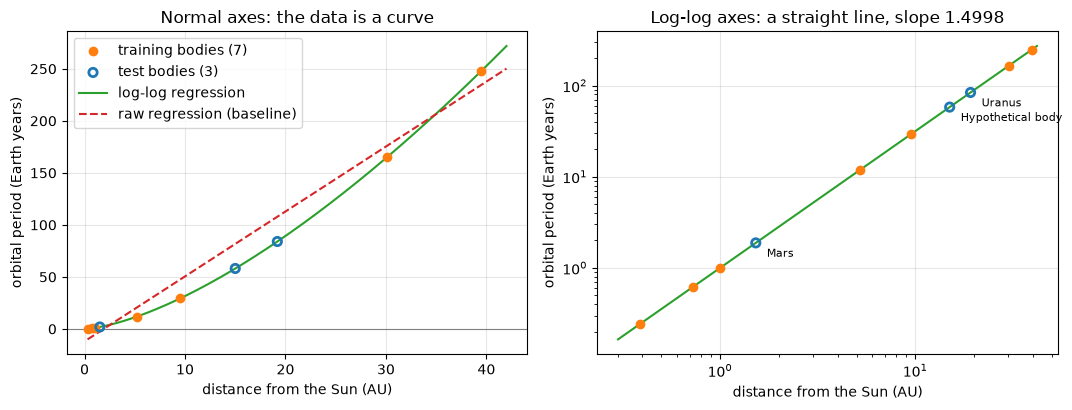

In [4]:
def loglog_line(distance):
    """The log-log model, converted back to years."""
    return 10 ** (fits["loglog"]["slope"] * np.log10(distance) + fits["loglog"]["intercept"])


def raw_line(distance):
    return fits["raw"]["slope"] * distance + fits["raw"]["intercept"]


def points(rows):
    return [r["distance_au"] for r in rows], [r["period_years"] for r in rows]


xs = np.linspace(0.3, 42, 300)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))

for ax in (left, right):
    ax.scatter(*points(train), color="tab:orange", zorder=3, label="training bodies (7)")
    ax.scatter(*points(test), facecolors="none", edgecolors="tab:blue", linewidths=2, zorder=3, label="test bodies (3)")
    ax.plot(xs, loglog_line(xs), color="tab:green", label="log-log regression")
    ax.set_xlabel("distance from the Sun (AU)")
    ax.set_ylabel("orbital period (Earth years)")
    ax.grid(alpha=0.3)

left.plot(xs, raw_line(xs), color="tab:red", linestyle="--", label="raw regression (baseline)")
left.axhline(0, color="gray", linewidth=0.8)
left.set_title("Normal axes: the data is a curve")
left.legend()

right.set_xscale("log")
right.set_yscale("log")
right.set_title(f"Log-log axes: a straight line, slope {fits['loglog']['slope']:.4f}")
for r in test:
    right.annotate(r["body"], (r["distance_au"], r["period_years"]), textcoords="offset points", xytext=(8, -10), fontsize=8)

fig.tight_layout()
# The synopsis uses this picture.
fig.savefig(ROOT / "docs" / "regression.png", dpi=200)
plt.show()

## 4. Predictions and error

The error measure is the mean absolute error (MAE): the average of |predicted - actual| over the test cases.

In [5]:
actual = np.array([r["period_years"] for r in test])

print(f"{'test case':<20}{'actual':>9}{'log-log':>9}{'raw':>9}")
for i, r in enumerate(test):
    print(f"{r['body']:<20}{actual[i]:>9.2f}{predictions['loglog'][i]:>9.2f}{predictions['raw'][i]:>9.2f}")

mae = {name: float(np.mean(np.abs(np.array(values) - actual))) for name, values in predictions.items()}
print(f"\nMAE log-log: {mae['loglog']:.2f} years")
print(f"MAE raw:     {mae['raw']:.2f} years")

test case              actual  log-log      raw
Mars                     1.88     1.88    -2.39
Uranus                  84.02    84.00   107.85
Hypothetical body       58.09    58.05    81.70

MAE log-log: 0.02 years
MAE raw:     17.24 years


## 5. Compared with the language model

The language model's answers are not produced here: they need Ollama and are written to `experiment/results.json` by `uv run python -m experiment.run_experiment`. This cell only reads that file and draws all four approaches next to the actual values.

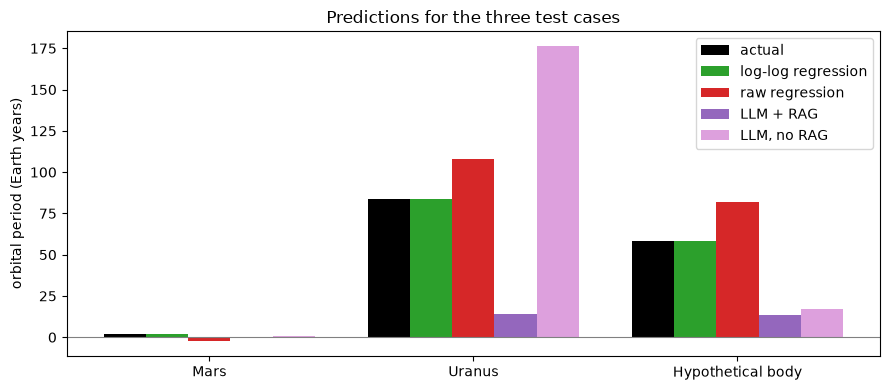

MAE log-log regression     0.02 years
MAE raw regression        17.24 years
MAE LLM + RAG             38.73 years
MAE LLM, no RAG           44.83 years


In [6]:
results = json.loads((ROOT / "experiment" / "results.json").read_text())
labels = {"loglog": "log-log regression", "raw": "raw regression", "llm_rag": "LLM + RAG", "llm_no_rag": "LLM, no RAG"}
colors = {"loglog": "tab:green", "raw": "tab:red", "llm_rag": "tab:purple", "llm_no_rag": "plum"}

cases = results["cases"]
x = np.arange(len(cases))
width = 0.16
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - 2 * width, [c["actual_years"] for c in cases], width, color="black", label="actual")
for i, key in enumerate(labels):
    ax.bar(x + (i - 1) * width, [c["predictions"][key] for c in cases], width, color=colors[key], label=labels[key])
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xticks(x, [c["body"] for c in cases])
ax.set_ylabel("orbital period (Earth years)")
ax.set_title("Predictions for the three test cases")
ax.legend()
fig.tight_layout()
plt.show()

for key, label in labels.items():
    print(f"MAE {label:<20}{results['summary']['mae'][key]:>7.2f} years")